# PML and periodic boundaries

This example simulates a plane wave that scatters off a dielectric cube.

A simulation box is finite, so every face needs a boundary condition that defines what happens to a wave when it reaches that face. This example uses the two most common choices, PML and periodic boundaries, and combines them in one simulation.

**PML (perfectly matched layer).** A PML is an absorbing layer at the edge of the box. Waves enter it without being reflected and are damped inside it, so they never come back. The box then behaves like open space in that direction. In theory the layer is reflectionless for all angles and frequencies. On a discrete grid a small reflection remains, and a thicker layer makes it smaller.

**Periodic boundary.** A periodic boundary connects opposite faces of the box. A wave that leaves through one face enters again through the opposite face, so the box behaves like one unit cell of an infinite array. This is also how we get an infinitely wide plane wave in a finite box.

**Setup.** We use PML on the two $z$-faces and periodic boundaries on the $x$- and $y$-faces. An $E_x$-polarized plane wave travels in $-z$ towards a dielectric cube. The aim is to show that these two boundary types together reproduce an ideal situation: an infinitely wide plane wave hitting an infinite square array of cubes, with open space above and below. The periodic faces let the wave fill the whole cross-section, so the cube is one element of an array with a period of 8 µm. The PML faces let the transmitted and reflected waves leave the box, so nothing comes back to disturb the result. In the video, the wavefronts should stay flat away from the cube, and no reflection should return from the $z$-faces.

A plain periodic boundary is enough here because the wave travels parallel to the side faces, so its in-plane wavevector is zero. For oblique incidence the fields on opposite faces differ by a phase factor, and a Bloch boundary is needed instead (`BlochBoundary` in `fdtdx`).

## 1. Imports

This cell imports the libraries the notebook uses. JAX provides the arrays and compiles the simulation function with `jax.jit`, which makes the run fast. `jax.numpy` is needed to set the data type of the simulation. Matplotlib draws the plot of the setup, and `fdtdx` provides the simulation objects and the solver. `Video` from IPython embeds the final video in the notebook, and `time` measures the runtime.

In [3]:
import time 
import jax
import jax.numpy as jnp
from matplotlib import pyplot as plt
import fdtdx
from IPython.display import Video

%matplotlib inline

## 2. RNG key and simulation config

Several `fdtdx` functions take a JAX random key. Nothing in this simulation is random, but the functions still expect one, so we create it first. The list `object_list` collects everything we place in the box in the following steps.

`SimulationConfig` holds the settings that apply to the whole run. The simulated time is 100 fs, which is long enough for the wave to reach the cube, pass it and leave through the PML, with time left for the fields to settle. The grid spacing is 100 nm. At a wavelength of 1.55 µm this gives about 15 cells per wavelength in vacuum and about 10 inside the cube (refractive index $\approx 1.58$), which is enough to resolve the wave. `dtype=jnp.float32` uses single precision, which is accurate enough here and faster than double precision.

`courant_factor=0.99` sets the time step to 99% of the largest stable value. In 3D the stability limit of the Yee scheme is $c\,\Delta t / \Delta x \leq 1/\sqrt{3}$, and a larger time step makes the simulation blow up.

In [6]:
key = jax.random.PRNGKey(42)
object_list = []

config = fdtdx.SimulationConfig(
    time=100e-15,          # total simulated time: 100 fs
    grid=fdtdx.UniformGrid(spacing=100e-9),     # Yee-cell edge length: 100 nm (dx = dy = dz)
    dtype=jnp.float32,
    courant_factor=0.99,
)

## 3. Simulation volume

The `SimulationVolume` defines the box and its background material. Here the box is $8 \times 8 \times 10$ µm of vacuum ($\varepsilon = \mu = 1$). The box is longer in $z$ because the wave travels along $z$ and the source, the cube and the PML layers all need room there. The width of 8 µm in $x$ and $y$ is the period of the cube array. With a 2 µm cube, neighboring cubes are 6 µm apart, about four wavelengths.

In [9]:
volume = fdtdx.SimulationVolume(
    partial_real_shape=(8e-6, 8e-6, 10e-6),   # 8 x 8 x 10 micron box    
    material=fdtdx.Material(permittivity=1.0, permeability=1.0),
)
object_list.append(volume)
constraints = []

## 4. Boundaries

The boundaries are what turn this finite box into a plane wave on an infinite array, so we set them before placing anything else. `BoundaryConfig.from_uniform_bound` sets the same boundary type on all six faces, and `override_types` changes selected faces. We make every face periodic and then override the two $z$-faces with PML. The wave travels along $z$, so those are the faces it has to leave through. The $x$- and $y$-faces are parallel to the propagation direction, so they are periodic.

- `thickness=10` is the PML thickness in cells, which is 1 µm at this resolution. Periodic faces are always one cell thick, so the value only applies to the PML.
- `fdtdx` uses the convolutional PML (CPML). Inside the layer the wave decays exponentially, and it is mostly gone by the time it reaches the outer edge of the box.
- A periodic boundary in `fdtdx` is a Bloch boundary with zero phase shift between the two faces.

In [12]:
bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(
    boundary_type="periodic",       # default: x, y    
    thickness=10,                   # PML thickness in cells    
    override_types={"min_z": "pml", "max_z": "pml"},  # override z faces
)
bound_dict, bound_constraints = fdtdx.boundary_objects_from_config(bound_cfg, volume)
object_list.extend(bound_dict.values())
constraints.extend(bound_constraints)

## 5. Plane-wave source

The source launches the wave that hits the cube. It is an $E_x$-polarized plane wave with a wavelength of 1.55 µm that travels in the $-z$ direction. A plane wave is the natural choice here because the periodic boundaries make the box a unit cell of an infinite array, and a plane wave fills such an array uniformly.

- `partial_grid_shape=(None, None, 1)` makes the source one cell thick in $z$.
- `source.same_size(volume, axes=(0, 1))` makes it span the whole $x$-$y$ cross-section.
- `direction="-"` makes it propagate towards decreasing $z$.

The source covers the full cross-section and the $x$- and $y$-faces are periodic, so the source has no edges. The amplitude is therefore the same everywhere in the plane, unlike a Gaussian beam, which falls off away from its axis.

In [15]:
source = fdtdx.UniformPlaneSource(
    partial_grid_shape=(None, None, 1),
    fixed_E_polarization_vector=(1, 0, 0),
    wave_character=fdtdx.WaveCharacter(wavelength=1.55e-6),  # telecom C-band
    direction="-",
)
object_list.append(source)
constraints.extend([
    source.place_relative_to(
        volume, axes=(0, 1, 2),
        own_positions=(0, 0, 1), other_positions=(0, 0, 1),
        margins=(0, 0, -1.5e-6),  # sit 1.5 um in front of the +z PML
    ),
    source.same_size(volume, axes=(0, 1)),  # cover the entire x-y face
])

## 6. Dielectric cube

The cube is the object the wave scatters from. Without it the wave would simply cross the box, and there would be nothing to show. The cube has $\varepsilon = 2.5$ and an edge length of 2 µm, and it sits at the center of the box, away from both the PML and the periodic faces. The permittivity is high enough to cause a clear reflection, which forms an interference pattern with the incoming wave. You can remove the cube to see the wave travel through plain vacuum.

In [18]:
cube = fdtdx.UniformMaterialObject(
    partial_real_shape=(2e-6, 2e-6, 2e-6),
    material=fdtdx.Material(permittivity=2.5),
    name="Cube",
)
object_list.append(cube)
constraints.append(cube.place_at_center(volume))

## 7. Detector

To see what the wave does, we need to record the fields. An `EnergyDetector` stores the electromagnetic energy density every third time step (`interval=3`). Recording every step would need much more memory, and every third step still gives a smooth video. With `as_slices=True` the detector stores 2D slices through the volume instead of the full 3D data, and the video is made from these slices. The detector covers the whole volume, so the PML layers are recorded as well.

In [21]:
video = fdtdx.EnergyDetector(
    name="Video",
    as_slices=True,
    switch=fdtdx.OnOffSwitch(interval=3),
    exact_interpolation=True,
)
object_list.append(video)
constraints.extend(video.same_position_and_size(volume))

## 8. Resolve constraints and plot the setup

`fdtdx.place_objects` turns the relative placement constraints, such as "put the cube at the center of the box", into positions on the grid. It returns the placed objects, the field arrays, the parameters and an updated config. Before running, we plot the geometry to check that the source, the cube and the PML layers are where we intend them. A wrong placement is easier to catch here than in the video. The video detector is left out of the plot because it covers the whole box and would hide the other objects.

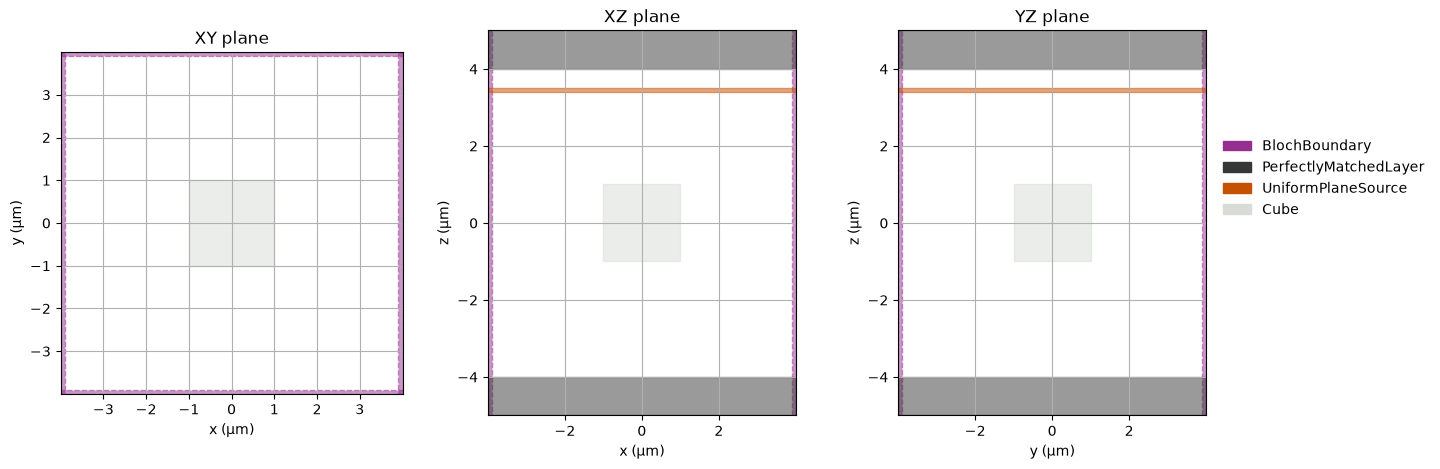

In [24]:
key, subkey = jax.random.split(key)
objects, arrays, params, config, _ = fdtdx.place_objects(
    object_list=object_list, config=config, constraints=constraints, key=subkey,
)

fig = fdtdx.plot_setup(config=config, objects=objects, exclude_object_list=[video])
plt.show()

## 9. Run the simulation

`sim_fn` runs the simulation. It applies the material parameters with `apply_params`, runs the FDTD time loop with `run_fdtd` and returns the final arrays, which include the detector recordings. We compile it with `jax.jit`, so the runtime printed below includes the compilation time as well.

In [27]:
def sim_fn(params, arrays, key):
    arrays, new_objects, _ = fdtdx.apply_params(arrays, objects, params, key)
    final_state = fdtdx.run_fdtd(arrays=arrays, objects=new_objects, config=config, key=key)
    _, arrays = final_state
    return arrays


jitted_sim = jax.jit(sim_fn)

t0 = time.time()
new_arrays = jitted_sim(params, arrays, subkey)
print(f"Simulation runtime: {time.time() - t0:.2f} s")

FDTD (checkpointed):   0%|                            | 0/525 [00:00<?, ?step/s]

Simulation runtime: 2.06 s


## 10. Video

The detector recorded the energy density over time. `draw_plot` renders the recorded slices into a video with three panels, showing the $x$-$y$, $x$-$z$ and $y$-$z$ planes. In the $x$-$z$ and $y$-$z$ panels the wave travels from top to bottom. The wavefronts should stay flat, the wave should disappear at the $z$-faces without a visible reflection, and the part reflected by the cube should form an interference pattern on the source side.

In [30]:
video_paths = objects["Video"].draw_plot(new_arrays.detector_states["Video"])

if isinstance(video_paths, (list, tuple)):
    path_to_show = video_paths[0]
elif isinstance(video_paths, dict):
    path_to_show = list(video_paths.values())[0]
else:
    path_to_show = video_paths

display(Video(path_to_show, embed=True))

## 11. References

1. K. S. Yee, "Numerical solution of initial boundary value problems involving Maxwell's equations in isotropic media," *IEEE Trans. Antennas Propag.*, 14(3):302–307, 1966.
2. A. Taflove and S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*, 3rd ed., Artech House, 2005.
3. J.-P. Bérenger, "A perfectly matched layer for the absorption of electromagnetic waves," *J. Comput. Phys.*, 114(2):185–200, 1994.
4. J. A. Roden and S. D. Gedney, "Convolution PML (CPML): An efficient FDTD implementation of the CFS-PML for arbitrary media," *Microw. Opt. Technol. Lett.*, 27(5):334–339, 2000.
5. J. B. Schneider, *Understanding the Finite-Difference Time-Domain Method*, 2010 (free online textbook).
6. Y. Mahlau, F. Schubert, L. Berg, B. Rosenhahn, "FDTDX: High-Performance Open-Source FDTD Simulation with Automatic Differentiation," *J. Open Source Softw.*, 11(117):8912, 2026.